# The moving sofa

What is the largest sofa that can be carried around a right-angled corner of a hallway of width 1? Leo Moser asked
this in 1966. Hammersley found a sofa of area π/2 + 2/π, about 2.2074, in 1968, and Gerver found one of about 2.2195
in 1992. No larger sofa is known.

The sofa has to stay inside the hallway in every position of its motion. Seen from the sofa, the hallway moves
instead, so for a given motion, the largest sofa is the intersection of the hallway in all its positions. Here, one
intersection gives Hammersley's sofa, and a search over the motion with SciPy comes within 0.0001 of Gerver's.

![The sofa found by the search, carried around the corner of the hallway](../_static/gallery/moving-sofa.gif){.result}

In [1]:
import math

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from scipy.optimize import minimize
import planex as px

## The hallway

The hallway has two arms of width 1, one along x and one along y, that meet at a right angle. Both arms are cut off
at a length of 6, far longer than any sofa. The inner corner of the hallway lies at the origin.

In [2]:
horizontal = px.QuickSketch((-6, 0)).Rectangle(7, 1).Face()
vertical = px.QuickSketch((0, -6)).Rectangle(1, 7).Face()
hallway = horizontal + vertical

Seen from the sofa, the hallway turns by an angle t from 0 to 90° while the sofa goes around the corner, and its
inner corner moves along a path p(t). The sofa is what all positions have in common:

- the first arm at the start, since the sofa comes along that arm;
- the whole hallway at every angle in between;
- the second arm at the end, since the sofa leaves along that arm.

`sofa` intersects these positions for a path, with n steps of the angle.

In [3]:
def placed(face, path, t):
    return face.Rotated((0, 0), math.degrees(t)).Translated(path(t))


def sofa(path, n):
    turns = [placed(hallway, path, math.pi / 2 * k / n) for k in range(1, n)]
    start, end = placed(horizontal, path, 0), placed(vertical, path, math.pi / 2)
    return px.Intersect([start, *turns, end])

## Hammersley's sofa

In Hammersley's motion, the inner wall of the first arm always runs through the point A = (−2/π, 0) of the sofa, and
the inner wall of the second arm through B = (2/π, 0). The two walls are perpendicular, so by Thales's theorem the
inner corner moves on the semicircle over AB, of radius 2/π: p(t) = 2/π (cos 2t, sin 2t).

Between two steps, the intersection leaves a little too much of the sofa, and this error shrinks as 1/n. The error
times n settles at about 0.64:

In [4]:
def hammersley(t):
    return (2 / math.pi * math.cos(2 * t), 2 / math.pi * math.sin(2 * t))


exact = math.pi / 2 + 2 / math.pi
areas = {}
for n in (90, 270, 810, 2430):
    areas[n] = sofa(hammersley, n).mass
    error = areas[n] - exact
    print(n, "steps: area", areas[n], "error", error, "error times n", error * n)

90 steps: area 2.2144655963589552 error 0.0070494971964771835 error times n 0.6344547476829465
270 steps: area 2.209771224746801 error 0.002355125584323048 error times n 0.6358839077672229
810 steps: area 2.2082017447113813 error 0.0007856455489032577 error times n 0.6363728946116387
2430 steps: area 2.2076780486697483 error 0.0002619495072702094 error times n 0.6365373026666088


Because the error is proportional to 1/n, two results remove it: 2 A(2n) − A(n) is the area without the error. From
1215 and 2430 steps, it agrees with π/2 + 2/π to about seven digits:

In [5]:
extrapolated = 2 * sofa(hammersley, 2430).mass - sofa(hammersley, 1215).mass
print("extrapolated", extrapolated, "exact", exact, "difference", extrapolated - exact)

extrapolated 2.20741616689293 exact 2.207416099162478 difference 6.773045191366123e-08


The sofa consists of two quarter discs of radius 1 on either side of a block of 4/π × 1, with a half disc of radius
2/π cut out of the block. The figure shows it inside some of the hallway's positions.

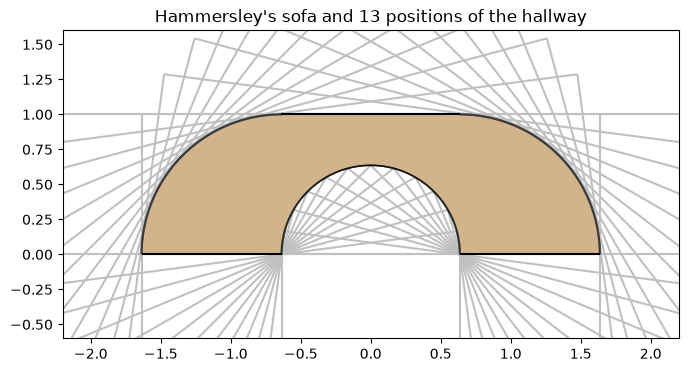

In [6]:
ham = sofa(hammersley, 720)
fig, ax = plt.subplots(figsize=(8, 4))
for k in range(0, 13):
    position = placed(hallway, hammersley, math.pi / 2 * k / 12)
    position.Plot(ax=ax, face_col=None, line_col="silver", legend=False)
ham.Plot(ax=ax, face_col="tan", legend=False)
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-2.2, 2.2)
ax.set_ylim(-0.6, 1.6)
ax.set_title("Hammersley's sofa and 13 positions of the hallway");

## A better motion

Hammersley's semicircle is not the best path. The search lets SciPy's Nelder–Mead method change it with six
coefficients. Each term keeps the motion symmetric, as it is in Hammersley's: under t → 90° − t, the horizontal part
of p changes its sign and the vertical part stays. The vertical part is 0 at the start, so the sofa stays on the
floor of the first arm. The search starts from Hammersley's path. A poor path can split the
intersection into pieces, so the search counts the largest piece only.

In [7]:
def path(c):
    def p(t):
        x = c[0] * math.cos(2 * t) + c[1] * math.cos(6 * t) + c[2] * math.cos(10 * t)
        y = c[3] * math.sin(2 * t) + c[4] * math.sin(6 * t) + c[5] * (math.cos(4 * t) - 1)
        return (x, y)
    return p


def area(c, n=360):
    return max(face.mass for face in sofa(path(c), n).faces)


start = [2 / math.pi, 0, 0, 2 / math.pi, 0, 0]
options = dict(maxiter=1500, xatol=1e-6, fatol=1e-8)
result = minimize(lambda c: -area(c), start, method="Nelder-Mead", options=options)
best = path(result.x)
print(result.nfev, "sofas tried, coefficients", result.x.round(4))

884 sofas tried, coefficients [ 0.6069  0.0053  0.0018  0.7316 -0.0065  0.0365]


The same extrapolation as above gives the area of the best sofa without the error of the steps. It is within about
0.0001 of Gerver's sofa, whose area Romik computed as 2.21953166887…:

In [8]:
extrapolated = 2 * area(result.x, 2880) - area(result.x, 1440)
gerver = 2.21953166887197
print("best sofa", extrapolated, "Gerver", gerver, "difference", extrapolated - gerver)

best sofa 2.2194144857580755 Gerver 2.21953166887197 difference -0.00011718311389463665


The sofa found by the search is a little narrower than Hammersley's. It gives up some area at its ends and at the
top of its cut-out, which is taller, and gains more at its upper shoulders and at the sides of the cut-out near the
floor. The two differences of the sofas show what is gained and lost:

gained 0.05335249944375165 lost 0.04141830825108156


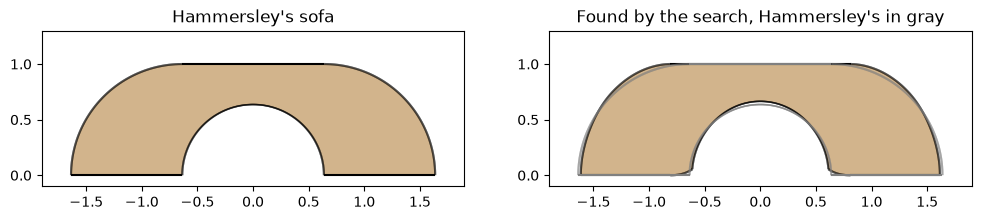

In [9]:
better = sofa(best, 720)
print("gained", (better - ham).mass, "lost", (ham - better).mass)
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.4))
ham.Plot(ax=left, face_col="tan", legend=False)
better.Plot(ax=right, face_col="tan", legend=False)
ham.Plot(ax=right, face_col=None, line_col="gray", legend=False)
left.set_title("Hammersley's sofa")
right.set_title("Found by the search, Hammersley's in gray")
for ax in (left, right):
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlim(-1.9, 1.9)
    ax.set_ylim(-0.1, 1.3);

## Around the corner

Back in the hallway, the sofa moves the other way: at the angle t, it is turned back by t about the inner corner after
p(t) is subtracted. It comes along the first arm, turns, and leaves along the second.

In [10]:
fig, ax = plt.subplots(figsize=(5, 5))


def carried(k):
    if k < 10:
        t, shift = 0.0, (-(10 - k) * 0.3, 0)
    elif k < 70:
        t, shift = math.pi / 2 * (k - 10) / 60, (0, 0)
    else:
        t, shift = math.pi / 2, (0, -(k - 69) * 0.3)
    x, y = best(t)
    turned = better.Translated((-x, -y)).Rotated((0, 0), -math.degrees(t))
    return turned.Translated(shift)


def frame(k):
    ax.clear()
    hallway.Plot(ax=ax, face_col="whitesmoke", legend=False)
    carried(k).Plot(ax=ax, face_col="tan", legend=False)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlim(-4.5, 1.5)
    ax.set_ylim(-4.5, 1.5)
    ax.axis("off")


animation = FuncAnimation(fig, frame, frames=80, interval=60)
plt.close(fig)
HTML(animation.to_jshtml())

In [11]:
import sys
sys.path.insert(0, "..")
from gallery import save_animation
save_animation(animation, "moving-sofa")